In [2]:
# Permite importar src/ desde la carpeta notebooks/
import sys
from pathlib import Path
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ))

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from src.config import DIR_DATA_RAW

pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", "{:,.2f}".format)
sns.set_theme(style="whitegrid")

In [3]:
archivos = sorted((DIR_DATA_RAW / "telemetria").glob("*.parquet"))
df = pd.concat([pd.read_parquet(a) for a in archivos], ignore_index=True)

df["fecha"] = pd.to_datetime(df["fecha"], errors="coerce")
df["ep"] = df["ep"].astype(str).str.strip().str.upper()

print(f"{len(df):,} filas | {df['ep'].nunique()} embarcaciones")
df.head()

198,598 filas | 15 embarcaciones


,id,ep,fecha,Latitud,Longitud,Velocidad,Rumbo,gal_h,rpm,origen
0,01343906SKYFE67,CARIBE,2026-04-05 10:32:25,-11.99,-77.16,0.30,3,3.70,449.00,mp_e
1,01343906SKYFE67,CARIBE,2026-04-05 10:47:31,-11.99,-77.16,0.20,3,3.43,450.00,mp_e
2,01343906SKYFE67,CARIBE,2026-04-05 11:02:15,-11.99,-77.16,0.10,1,3.17,450.00,mp_e
3,01343906SKYFE67,CARIBE,2026-04-05 11:17:10,-11.99,-77.16,0.00,0,3.17,450.00,mp_e
4,01343906SKYFE67,CARIBE,2026-04-05 11:32:07,-11.99,-77.16,0.20,3,3.17,450.00,mp_e


In [4]:
resumen = df.groupby("origen").agg(
    filas=("ep", "size"),
    embarcaciones=("ep", "nunique"),
    desde=("fecha", "min"),
    hasta=("fecha", "max"),
)
display(resumen)

print("\nNulos por columna (%):")
display((df.isna().mean() * 100).round(2).to_frame("% nulos").T)

,filas,embarcaciones,desde,hasta
origen,,,,
mp_e,7361,4,2026-04-04 11:23:24,2026-10-16 15:47:14
mp_e_h,62151,4,2025-01-01 00:02:05,2025-12-31 23:53:24
mp_m,12117,10,2026-04-04 11:02:06,2026-10-16 11:28:14
mp_m_h,116969,11,2025-01-01 00:00:09,2025-12-31 23:56:02



Nulos por columna (%):


,id,ep,fecha,Latitud,Longitud,Velocidad,Rumbo,gal_h,rpm,origen
% nulos,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00


origen              mp_e    mp_e_h      mp_m     mp_m_h
Velocidad count 7,361.00 62,151.00 12,117.00 116,969.00
          mean      6.82      7.72      6.10       7.44
          std       5.17      5.00      4.92       5.05
          min       0.00      0.00      0.00       0.00
          5%        0.10      0.20      0.20       0.20
          50%       9.80     10.60      8.00      10.40
          95%      12.60     12.80     11.90      12.70
          max      15.20     15.70     13.60      19.40
gal_h     count 7,361.00 62,151.00 12,117.00 116,969.00
          mean     39.69     44.83    339.21      42.44
          std      32.87     31.25  1,377.87      28.91
          min       3.17      3.17      0.10       0.10
          5%        3.17      3.17      2.10       2.40
          50%      44.12     55.48     28.60      53.50
          95%      86.92     86.92     83.00      83.80
          max      87.19     87.19  6,553.50     100.00
rpm       count 7,361.00 62,151.00 12,117.00 116,969.00
          mean    881.72    963.93    858.90     896.12
          std     344.67    334.34    349.98     314.15
          min     339.00    279.00      1.00       1.00
          5%      449.00    449.00    443.00     436.00
          50%   1,095.00  1,206.00    874.00     917.00
          95%   1,238.00  1,239.00  1,214.00   1,231.00
          max   1,252.00  1,295.00  8,502.00   1,270.00

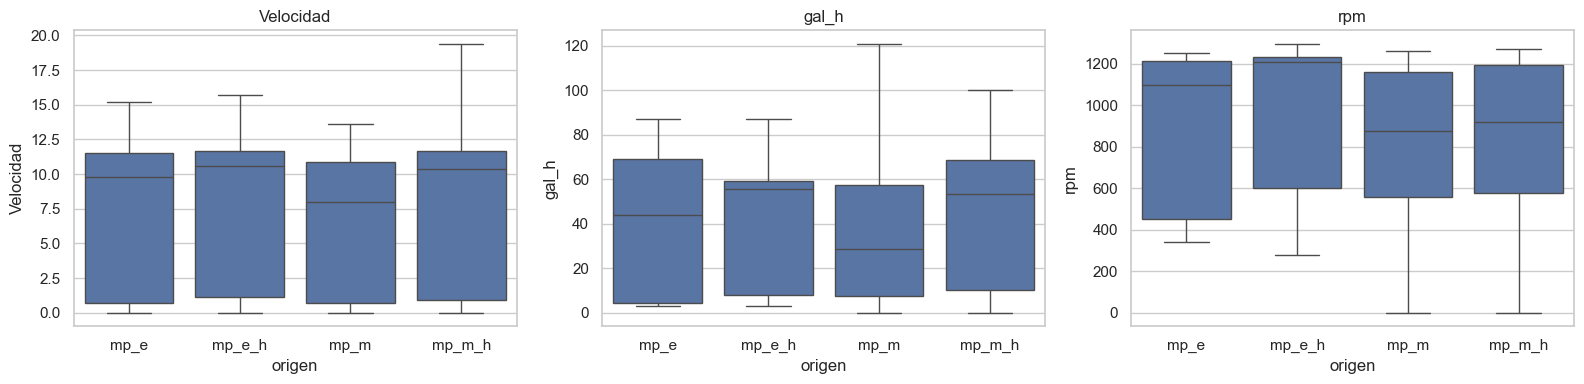

In [5]:
cols = ["Velocidad", "gal_h", "rpm"]
display(df.groupby("origen")[cols].describe(percentiles=[.05, .5, .95]).T)

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col in zip(axes, cols):
    sns.boxplot(data=df, x="origen", y=col, ax=ax, showfliers=False)
    ax.set_title(col)
plt.tight_layout()

In [6]:
# ¿Qué embarcaciones aparecen en qué fuente?
cruce = pd.crosstab(df["ep"], df["origen"])
display(cruce[(cruce > 0).sum(axis=1) > 1])  # las que están en más de una fuente

# ¿Registros repetidos (misma embarcación y mismo instante)?
dup = df.duplicated(subset=["ep", "fecha"], keep=False)
print(f"Registros duplicados por (ep, fecha): {dup.sum():,} ({dup.mean():.1%})")
display(df[dup].sort_values(["ep", "fecha"]).head(10))

origen,mp_e,mp_e_h,mp_m,mp_m_h
ep,,,,
ANCASH 2,514,8516,0,0
BLANDI,0,0,302,6672
CARIBE,1906,8441,0,0
CARMENCITA,0,0,13,19230
CRETA,0,0,2517,16491
CUZCO 4,1650,23280,0,0
DON ALFREDO,3291,21914,0,0
ERNESTINA,0,0,1668,4276
MARIA I,0,0,2130,2072


Registros duplicados por (ep, fecha): 6 (0.0%)


,id,ep,fecha,Latitud,Longitud,Velocidad,Rumbo,gal_h,rpm,origen
191001,15449,CRETA,2025-07-02 05:10:40,"5,400,000.00","10,800,000.00",1.60,0,72.50,"1,132.00",mp_m_h
191002,15450,CRETA,2025-07-02 05:10:40,"5,400,000.00","10,800,000.00",1.60,0,72.50,"1,132.00",mp_m_h
140386,10486,MARY,2025-12-03 10:20:21,"-733,790.00","-4,629,143.00",13.10,7,82.60,903.00,mp_m_h
140387,10487,MARY,2025-12-03 10:20:21,"-731,848.00","-4,631,868.00",13.40,7,81.90,903.00,mp_m_h
140392,10492,MARY,2025-12-03 10:20:53,"-744,719.00","-4,616,830.00",13.00,7,82.70,903.00,mp_m_h
140393,10493,MARY,2025-12-03 10:20:53,"-738,670.00","-4,624,790.00",13.30,7,82.10,900.00,mp_m_h


In [10]:
df["fecha"].min()

Timestamp('2025-01-01 00:00:09')

In [7]:
q = df[cols].quantile([0.001, 0.01, 0.5, 0.99, 0.999])
display(q)

print(f"RPM >= 2000:   {(df['rpm'] >= 2000).sum():,} filas")
print(f"gal_h >= 300: {(df['gal_h'] >= 300).sum():,} filas")
print(f"Velocidad > 15 nudos: {(df['Velocidad'] > 15).sum():,} filas")
print(f"Velocidad < 0 o gal_h < 0: {((df['Velocidad'] < 0) | (df['gal_h'] < 0)).sum():,} filas")

,Velocidad,gal_h,rpm
0.00,0.00,0.40,153.00
0.01,0.00,1.70,398.00
0.50,10.40,54.16,"1,108.00"
0.99,13.30,92.20,"1,244.00"
1.00,13.80,"6,551.90","1,255.00"


RPM >= 2000:   8 filas
gal_h >= 300: 569 filas
Velocidad > 15 nudos: 3 filas
Velocidad < 0 o gal_h < 0: 0 filas


,registros
ep,
DON ALFREDO,25205
CUZCO 4,24930
RODAS,20009
CARMENCITA,19243
CRETA,19008
MARIANGELLA,16162
SANTA ADELA II,15746
CARIBE,10347
POLAR I,10043


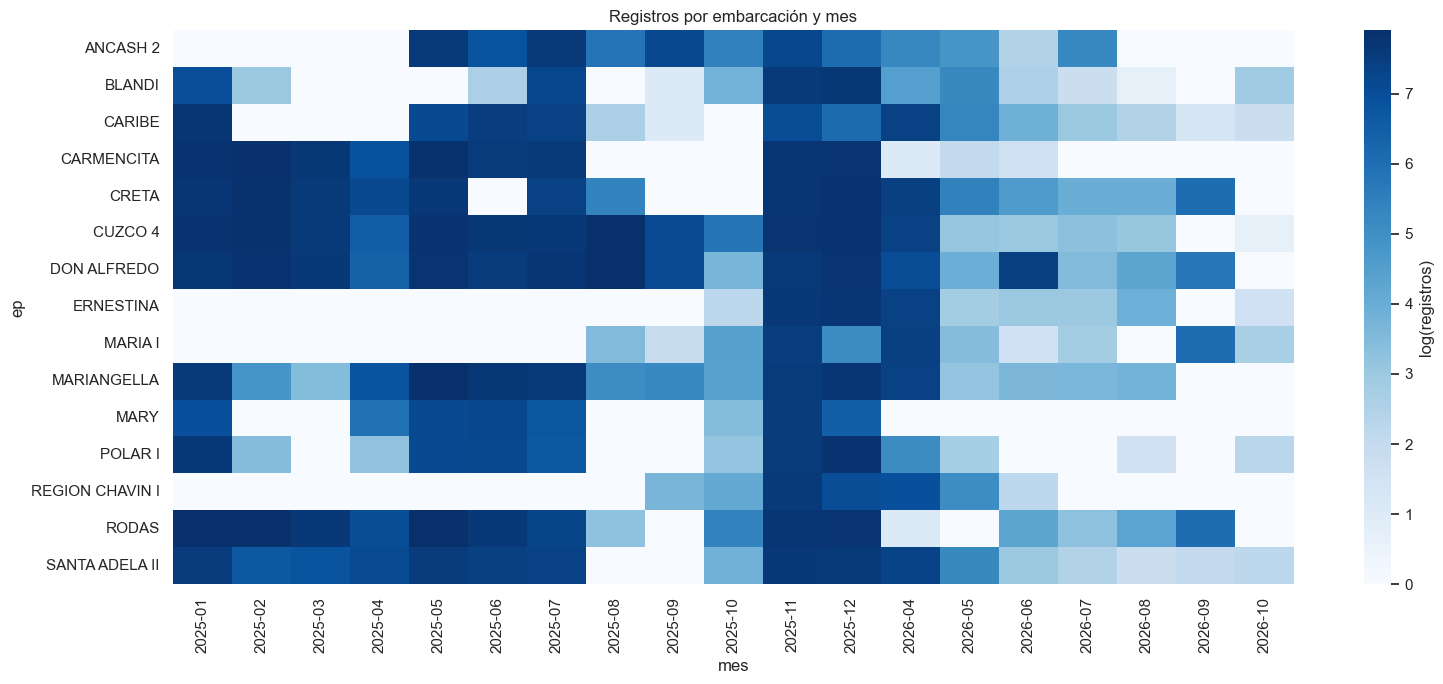

In [8]:
df["mes"] = df["fecha"].dt.to_period("M")
cobertura = df.pivot_table(index="ep", columns="mes", values="rpm", aggfunc="size", fill_value=0)

plt.figure(figsize=(16, 7))
sns.heatmap(np.log1p(cobertura), cmap="Blues", cbar_kws={"label": "log(registros)"})
plt.title("Registros por embarcación y mes")
plt.tight_layout()

display(df["ep"].value_counts().to_frame("registros"))